In [143]:

#Importing necessary libraries

import matplotlib.pyplot as plt
import numpy as np
import networkx as nx

In [144]:
#Intittializing the Adjacency matrix
A = nx.to_numpy_array(nx.karate_club_graph(),weight=None, dtype=int)

#defining the degree vectors

K=A.sum(axis=1).reshape(-1, 1)
Kt=np.transpose(K)
D=K@Kt

#number of edges
m=int(A.sum()/2)
print(m)

78


In [145]:
#Initializing the Modularity Matrix

B=A-D/(2*m)

In [146]:
#Initializing Bipartition

s=np.zeros((A.shape[0],1), dtype=int)

#Now we must maximize s, since all the soft assignment for now is 0)

#Let us define Q

st=np.transpose(s)

Q=st@B@s

#This section does not accomplish anything and is only for my own help

In [147]:
#Now our goal is to Maximize Qv by varying s and find the s resulting in the maximum Qvm, which we will use leading eigenvector for.

#Finding Leading Eigenvector of B

EVal,EVec=np.linalg.eigh(B)

EVec=EVec.tolist()
EVal=EVal.tolist()

LVal=max(EVal)
ind=EVal.index(LVal)
LVec=[row[ind] for row in EVec]

print(LVal,LVec)

4.977080225729886 [0.387542930321193, 0.2695574218932869, 0.1318989908275373, 0.2534523569522068, 0.13400323139230136, 0.14573804098532978, 0.14573804098532975, 0.20935953611336894, -0.05447571362472027, -0.04785237690915354, 0.13400323139230133, 0.07784278925909384, 0.12874396470296695, 0.13502860919769782, -0.13943288264641296, -0.13943288264641296, 0.058518211962265754, 0.13197981066297826, -0.13943288264641296, 0.05764888374730708, -0.13943288264641296, 0.13197981066297831, -0.13943288264641301, -0.2167471243435387, -0.056330496715049756, -0.0754003859034068, -0.11580256794135757, -0.10276486676894983, -0.06834027295276404, -0.20629456129341367, -0.09626390562457668, -0.1018567790813649, -0.3239045333397196, -0.36983786332806223]


In [148]:
#Now lets convert the leading eigenvector to have elements in -1 or 1 for assignment.
u1=list()
for i in LVec:
  if i>0:
    u1.append(1)
  else:
    u1.append(-1)

u=np.array(u1)
ut=u.T
Q=ut@B@u

#We can now find the modularity by taking 1/4m of the Q value

Modularity = Q.item()/(4*m)

print(Modularity)
print(u1)

0.37146614069691
[1, 1, 1, 1, 1, 1, 1, 1, -1, -1, 1, 1, 1, 1, -1, -1, 1, 1, -1, 1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]


In [149]:
#Let us now make the function to achieve each step to call recursively

def Modul(A,choice):
  K=A.sum(axis=1).reshape(-1, 1)
  Kt=np.transpose(K)
  D=K@Kt
  m=int(A.sum()/2)
  B=A-D/(2*m)
  EVal,EVec=np.linalg.eigh(B)
  EVec=EVec.tolist()
  EVal=EVal.tolist()
  LVal=max(EVal)
  ind=EVal.index(LVal)
  LVec=[row[ind] for row in EVec]
  u1=list()
  for i in LVec:
    if i>0:
      u1.append(1)
    else:
      u1.append(-1)
  u=np.array(u1)
  ut=u.T
  Q=ut@B@u
  Modularity = Q.item()/(4*m)
  if choice=="ModMat":
    return B
  elif choice=="Mod":
    return Modularity
  elif choice=="div":
    return u1
  elif choice=="Eigen":
    return LVal
  elif choice=="Evec":
    return u1
  else:
    print("Error, put correct term, returning None")
    return None


In [150]:
#Now we recursivelty split into communities, so let us create a function which simply takes the u and splits it into two communities.

#For this we would need a function which has both the orignal communities and the split (O is orignal community, u is the eigenvalue split)
def Community_split(O, v, ids):
  C1=list()
  C2=list()
  ids1=list()
  ids2=list()
  Count=0
  for i in v:
    if i==1:
      C1.append(O[Count,:])
      ids1.append(ids[Count])
    else:
      C2.append(O[Count,:])
      ids2.append(ids[Count])
    Count+=1
  C1=np.array(C1)
  C2=np.array(C2)
  C1new=list()
  C2new=list()
  Count=0
  for i in v:
    if i==1:
      C1new.append(C1[:,Count])
    else:
      C2new.append(C2[:,Count])
    Count+=1
  return (np.array(C1new), ids1), (np.array(C2new), ids2)

listc = [A]
idsc = [list(range(len(A)))]
listfinal = []
idsfinal = []
Iteration = {0: listc}
Iteration_ids = {0: idsc}
I = 0
while listc:
    listcnew = []
    idsnew = []
    for mat, ids in zip(listc, idsc):
        (a, ia), (b, ib) = Community_split(mat, Modul(mat, "div"), ids)
        listcnew.extend([a, b])
        idsnew.extend([ia, ib])
    listc = []
    idsc = []
    for mat, ids in zip(listcnew, idsnew):
        if Modul(mat, "Eigen") <= 1e-10:
            listfinal.append(mat)
            idsfinal.append(ids)
        else:
            listc.append(mat)
            idsc.append(ids)
    I += 1
    Iteration[I] = listc + listfinal
    Iteration_ids[I] = idsc + idsfinal
    
(W1, ids1), (W2, ids2) = Community_split(A, u1, list(range(len(A))))
print(W1)
print(W2)

#The code above is Claude enhanced after my own code. 
# The reason for this enhaancement was because my method of community splitting did not preserve the IDs of the nodes, I did not do it manually since 
# I am not completely familiar with matplotlib and did not know what waay of indexing was required to ensure proper excecution and creation of graph

# def Community_split(O,v):
#  C1=list()
#  C2=list()
#  Count=0
#  for i in v:
#    if i==1:
#      C1.append(O[Count,:])
#    else:
#      C2.append(O[Count,:])
#    Count+=1
#  C1=np.array(C1)
#  C2=np.array(C2)
#  C1new=list()
#  C2new=list()
#  Count=0
#  for i in v:
#    if i==1:
#      C1new.append(C1[:,Count])
#    else:
#      C2new.append(C2[:,Count])
#    Count+=1
#  return np.array(C1new),np.array(C2new)
#W1,W2=Community_split(A,u1)
#print(W1)
#print(W2)

#We have made the splitting function and now I can simply enter the community and the eigenvector to derive the splits.


[[0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1]
 [1 0 1 1 0 0 0 1 0 0 0 1 0 1 1 1]
 [1 1 0 1 0 0 0 1 0 0 0 1 0 0 0 0]
 [1 1 1 0 0 0 0 1 0 0 1 1 0 0 0 0]
 [1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0]
 [1 0 0 0 1 1 0 0 0 0 0 0 1 0 0 0]
 [1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1]
 [0 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0 1 1]
 [0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1]
 [0 0 0 0 

In [151]:
#Each community is stored as a matrix (listc) together with the list of original node IDs it contains (idsc).
#The IDs are needed later so that Graphing knows which nodes of the full graph belong to which community.
listc = [A]
idsc = [list(range(len(A)))]
listfinal = []
idsfinal = []
Iteration = {0: listc}
Iteration_ids = {0: idsc}
I = 0
while listc:
    listcnew = []
    idsnew = []
    for mat, ids in zip(listc, idsc):
        #the same +1/-1 vector from Modul splits both the matrix and its node IDs
        (a, ia), (b, ib) = Community_split(mat, Modul(mat, "div"), ids)
        listcnew.extend([a, b])
        idsnew.extend([ia, ib])
    listc = []
    idsc = []
    for mat, ids in zip(listcnew, idsnew):
        #a community whose leading eigenvalue is not positive cannot be split further
        if Modul(mat, "Eigen") <= 1e-10:
            listfinal.append(mat)
            idsfinal.append(ids)
        else:
            listc.append(mat)
            idsc.append(ids)
    I += 1
    #the snapshot of each iteration = communities still being split + communities that are finished
    #matrices and IDs are combined in the same order so they stay matched
    Iteration[I] = listc + listfinal
    Iteration_ids[I] = idsc + idsfinal

for i, j in Iteration.items():
  print(i)
  print(Iteration_ids[i])
  for a in j:
    print(a)
  print("\n\n")


# listc = [A]
#listfinal = []
#Iteration={0:listc}
#I=0
#while listc:
#    listcnew = []
#    for i in listc:
#        a, b = Community_split(i, Modul(i, "div"))
#        listcnew.extend([a, b])
#    listc = []
#    for i in listcnew:
#        if Modul(i, "Eigen") <= 1e-10:
#            listfinal.append(i)
#        else:
#           listc.append(i)
#    I+=1
#    Iteration[I]=listc+listfinal
#for i,j in Iteration.items():
#  print(i)
#  for a in j:
#    print(a)
#  print("\n\n\n\n") 
  
#  This here is the old code I used, the given code I will be using now is the code I enhaanced using Claaude

0
[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]]
[[0 1 1 ... 1 0 0]
 [1 0 1 ... 0 0 0]
 [1 1 0 ... 0 1 0]
 ...
 [1 0 0 ... 0 1 1]
 [0 0 1 ... 1 0 1]
 [0 0 0 ... 1 1 0]]



1
[[0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21], [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]]
[[0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1]
 [1 0 1 1 0 0 0 1 0 0 0 1 0 1 1 1]
 [1 1 0 1 0 0 0 1 0 0 0 1 0 0 0 0]
 [1 1 1 0 0 0 0 1 0 0 1 1 0 0 0 0]
 [1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0]
 [1 0 0 0 1 1 0 0 0 0 0 0 1 0 0 0]
 [1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1]
 [0 0 0 0 0 0

In [152]:
#While this loop works, it is incredible inefficiently computer and a better loop is necessary.

#Also, while yes, it gives us subgroups, we dont know if the modularity is decreasing or increasing, so let us check that first.

#the same code with the output being the elements with iteration corresponding to modularity instead of the matrices itself.

def ModularitySanitycheck(Modul):
    n = A.shape[0]
    m = A.sum() / 2
    B = Modul(A, "ModMat")
    s = Modul(A, "div")
    s_arr = np.array(s)

    print("B is symmetric:", np.allclose(B, B.T))
    print("every row of B sums to 0:", np.allclose(B.sum(axis=1), 0))

    ones = np.ones(n)
    print("trivial partition gives Q = 0:", np.isclose(ones @ B @ ones / (4*m), 0))

    print("labels are +1/-1, one per node:", len(s) == n and set(s) <= {1, -1})

    k = A.sum(axis=1)
    same = s_arr[:, None] == s_arr[None, :]
    Q_def = ((A - np.outer(k, k) / (2*m)) * same).sum() / (2*m)
    print("Modul's Q matches the definition (%.4f):" % Q_def, np.isclose(Modul(A, "Mod"), Q_def))

    print("flipping every sign leaves Q unchanged:", np.isclose(s_arr @ B @ s_arr, (-s_arr) @ B @ (-s_arr)))
    print("leading eigenvalue >= 0:", Modul(A, "Eigen") >= -1e-10)

ModularitySanitycheck(Modul)

B is symmetric: True
every row of B sums to 0: True
trivial partition gives Q = 0: True
labels are +1/-1, one per node: True
Modul's Q matches the definition (0.3715): True
flipping every sign leaves Q unchanged: True
leading eigenvalue >= 0: True


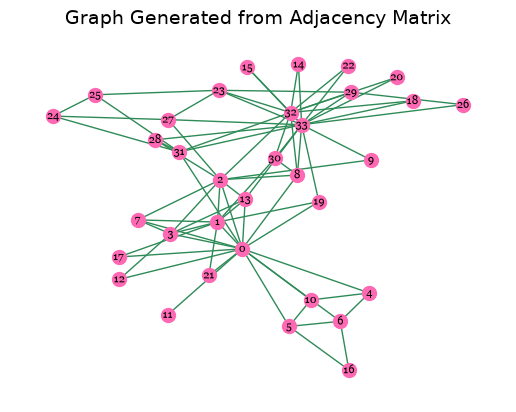

In [153]:
#Now, let us begin plotting each iteration of the spectral clustering, starting with the intial, unclustered graph
G=nx.from_numpy_array(A)
pos=nx.spring_layout(G)
nx.draw_networkx_nodes(G, pos, node_color="hotpink", node_size=100)
nx.draw_networkx_edges(G, pos, width=1, edge_color="seagreen")
nx.draw_networkx_labels(G, pos, font_size=8, font_family="Georgia", font_weight="normal")
plt.title("Graph Generated from Adjacency Matrix", fontsize=14)
plt.axis("off")
plt.show()

In [154]:
#Now to partition the graph, we will use the elements in our Iteration dictionary to create partitions

#I will use a recursive function to generalize this case and make it applicable to other graphs as well

#def Graphing(LI):
#    colours = ['red', 'green', 'blue', 'yellow', 'orange', 'purple',
#    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
#    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan',
#    'crimson', 'firebrick', 'darkred', 'tomato', 'salmon', 'hotpink', 'deeppink', 'maroon',
#    'darkorange', 'coral', 'gold', 'goldenrod', 'khaki',
#    'forestgreen', 'limegreen', 'seagreen', 'olive', 'darkgreen', 'lightgreen',
#    'navy', 'royalblue', 'steelblue', 'skyblue', 'dodgerblue', 'teal', 'turquoise',
#    'indigo', 'violet', 'orchid', 'chocolate', 'sienna']
#    for i in LI.keys():
#        if i==0:
#            G=nx.from_numpy_array(LI[0][0])
#           pos=nx.spring_layout(G)
#            nx.draw_networkx_nodes(G, pos, node_color="hotpink", node_size=100)
#            nx.draw_networkx_edges(G, pos, width=1, edge_color="seagreen")
#            nx.draw_networkx_labels(G, pos, font_size=8, font_family="Georgia", font_weight="normal")
#            plt.title("Graph Generated from Adjacency Matrix", fontsize=14)
#            plt.axis("off")
#            plt.show()
#        else:
#            G=nx.from_numpy_array(LI[0][0])
#            pos=nx.spring_layout(G)
#            for c, j in enumerate(LI[i]):
#                nx.draw_networkx_nodes(G, pos, nodelist=j, node_color=colours[c], node_size=100)
#            nx.draw_networkx_edges(G, pos, width=1, edge_color="seagreen", alpha=0.6)
#            nx.draw_networkx_labels(G, pos, font_size=8, font_family="Georgia", font_weight="normal")
#            plt.title("Graph Visualized of Iteration {i}")
#            plt.axis("off")
#            plt.show()
#Graphing(Iteration)

# Again, an old attempt written by myself to partition the graphs, the one below is edited by claude.

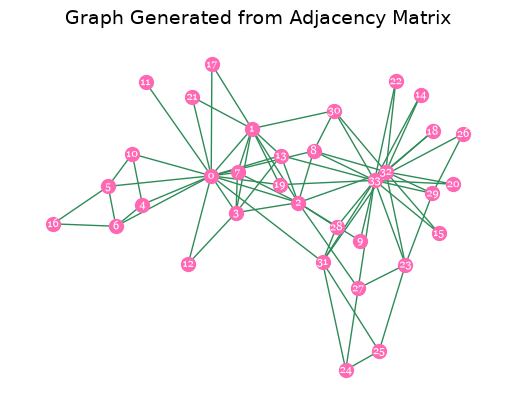

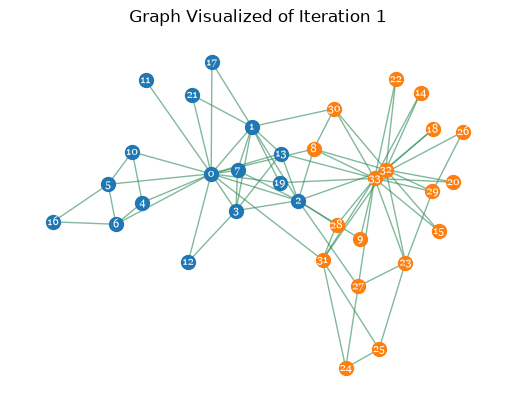

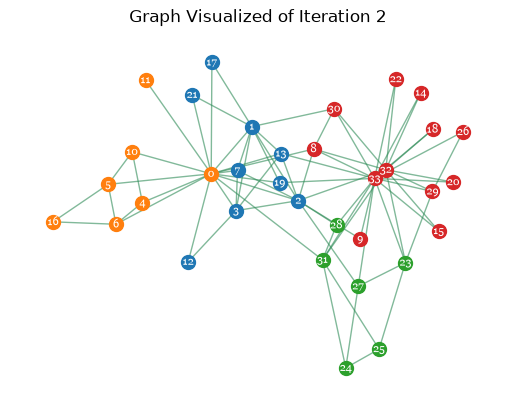

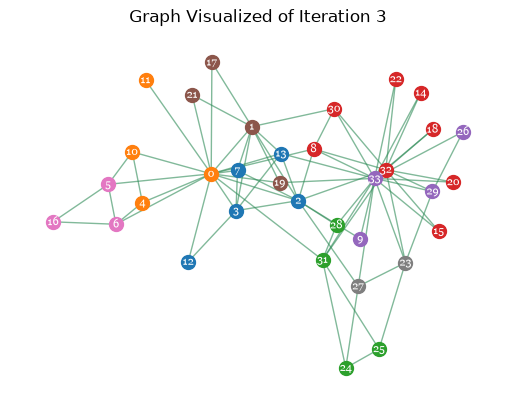

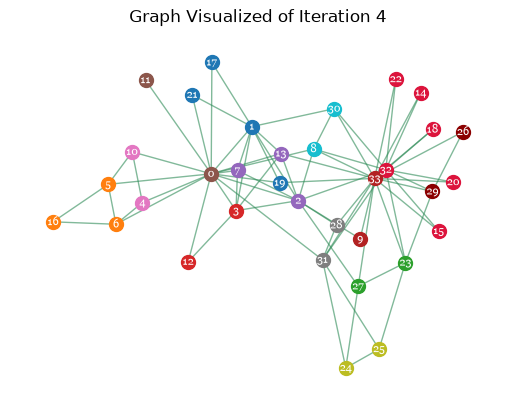

In [155]:
def Graphing(LI, LI_ids):
    colours = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan',
    'crimson', 'firebrick', 'darkred', 'tomato', 'salmon', 'hotpink', 'deeppink', 'maroon',
    'darkorange', 'coral', 'gold', 'goldenrod', 'khaki',
    'forestgreen', 'limegreen', 'seagreen', 'olive', 'darkgreen', 'lightgreen',
    'navy', 'royalblue', 'steelblue', 'skyblue', 'dodgerblue', 'teal', 'turquoise',
    'indigo', 'violet', 'orchid', 'chocolate', 'sienna']
    G = nx.from_numpy_array(LI[0][0])
    pos = nx.spring_layout(G, seed=7)
    for i in LI.keys():
        if i == 0:
            nx.draw_networkx_nodes(G, pos, node_color="hotpink", node_size=100)
            nx.draw_networkx_edges(G, pos, width=1, edge_color="seagreen")
            nx.draw_networkx_labels(G, pos, font_size=8, font_family="Georgia", font_weight="normal", font_color="white")
            plt.title("Graph Generated from Adjacency Matrix", fontsize=14)
            plt.axis("off")
            plt.show()
        else:
            for c, j in enumerate(LI_ids[i]):
                nx.draw_networkx_nodes(G, pos, nodelist=j, node_color=colours[c], node_size=100)
            nx.draw_networkx_edges(G, pos, width=1, edge_color="seagreen", alpha=0.6)
            nx.draw_networkx_labels(G, pos, font_size=8, font_family="Georgia", font_weight="normal", font_color="white")
            plt.title(f"Graph Visualized of Iteration {i}")
            plt.axis("off")
            plt.show()

Graphing(Iteration, Iteration_ids)

In [156]:
#Now that our iterations are done, let us try to get a program Such that we can compute Node metrics and visualize it

def Node_Metric(Graph):
    DegCen=nx.degree_centrality(Graph)
    BwCen=nx.betweenness_centrality(Graph)
    ClCen=nx.closeness_centrality(Graph)
    CluCo=nx.clustering(Graph)
    return DegCen,BwCen,ClCen,CluCo

#We also add another function to build a graph after each iteration without intergraph edges, in order to colaculate the metrics.

def Iteration_Graph(A0, groups):
    M = np.zeros_like(A0)
    for ids in groups:
        M[np.ix_(ids, ids)] = A0[np.ix_(ids, ids)]
    return nx.from_numpy_array(M)



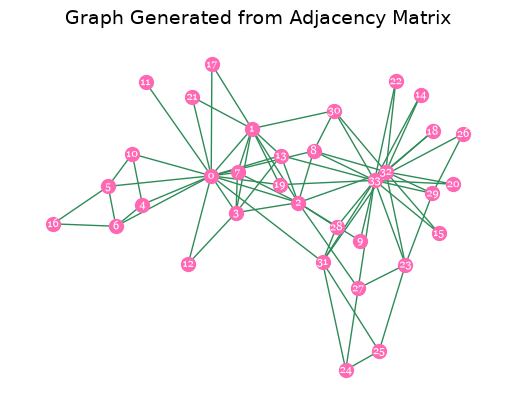

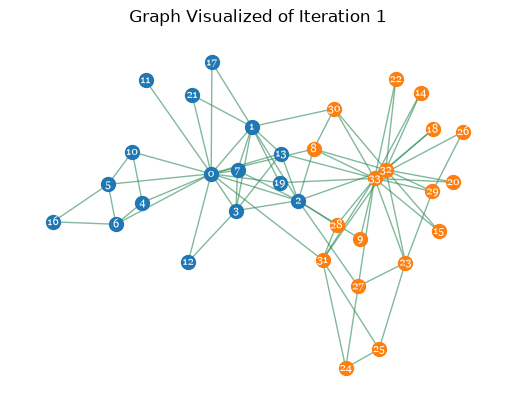

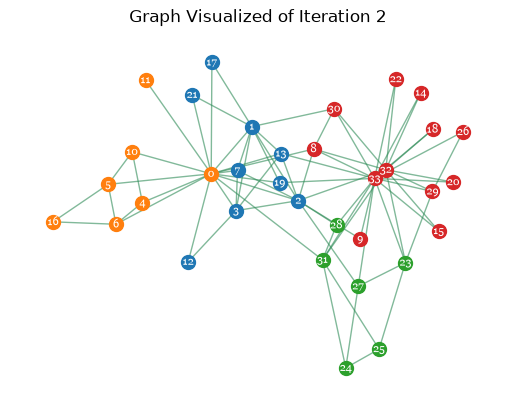

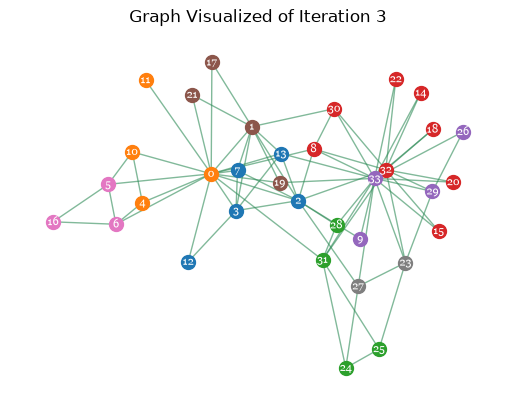

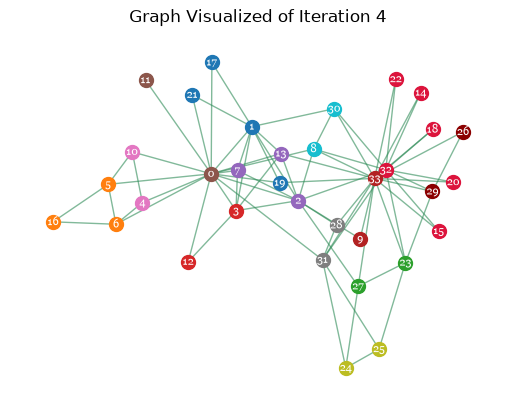

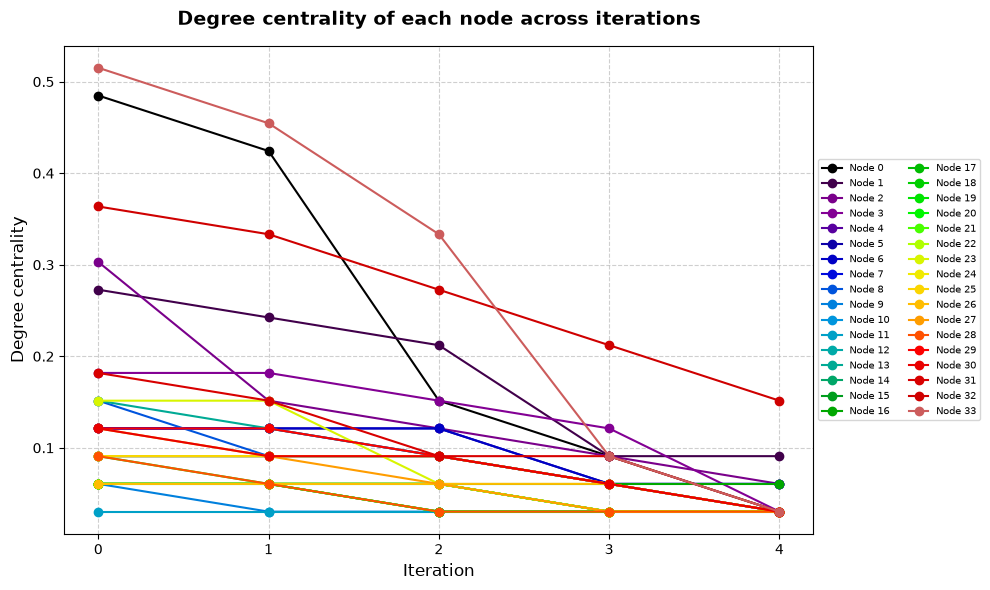

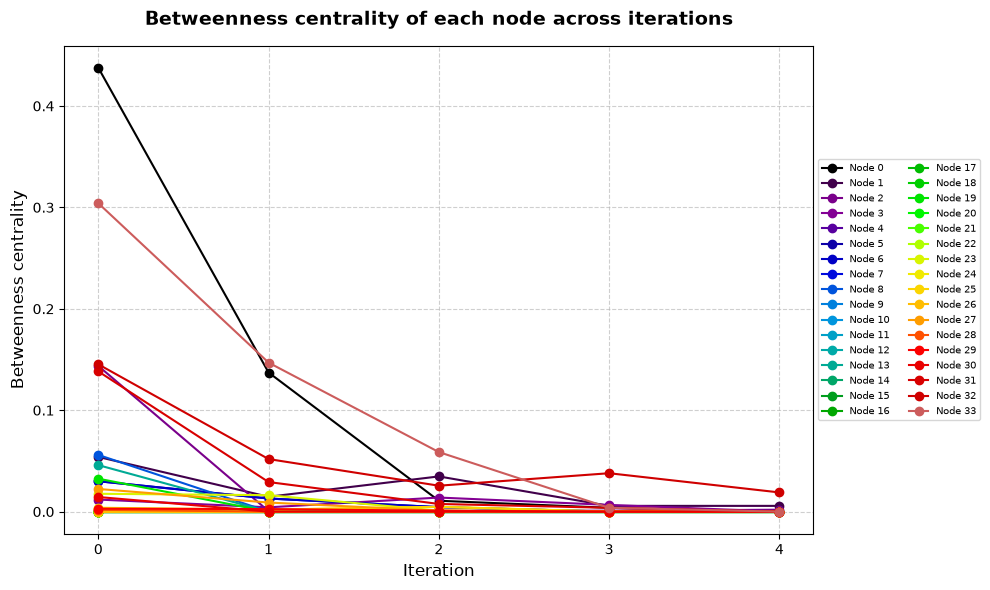

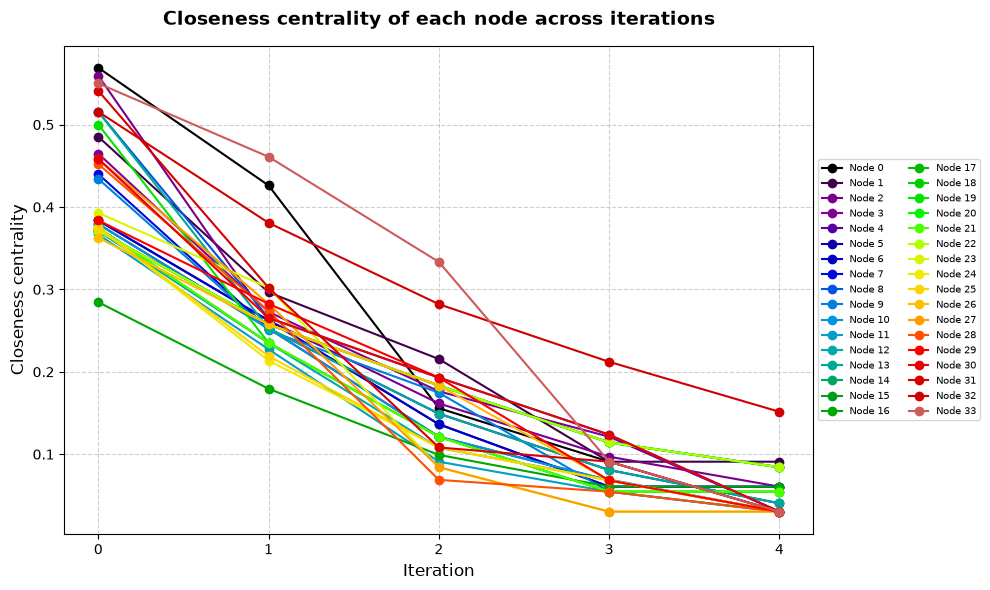

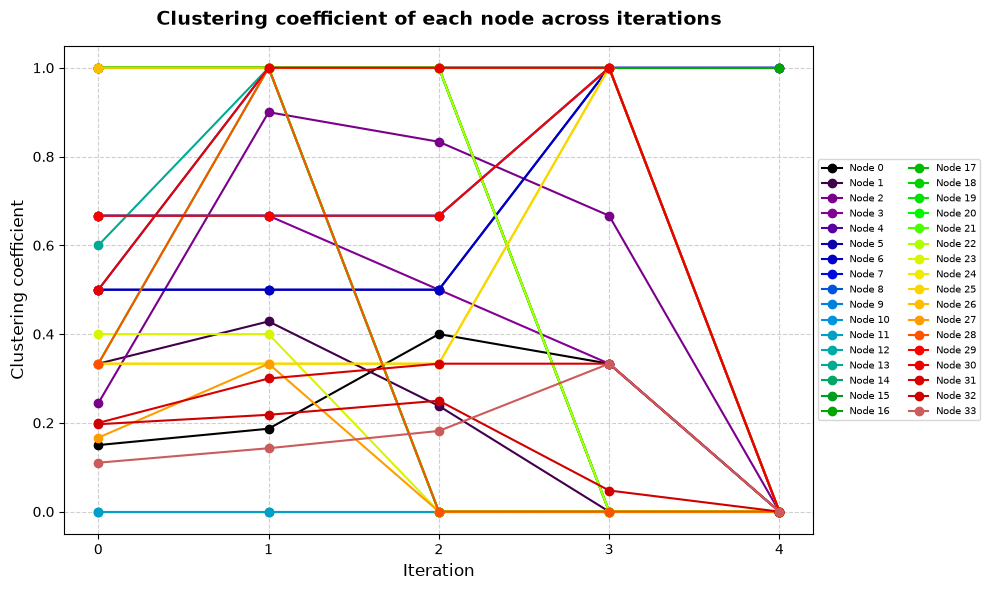

In [158]:
#Adding the required Metric nodes

def Graphing(LI, LI_ids):
    colours = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan',
    'crimson', 'firebrick', 'darkred', 'tomato', 'salmon', 'hotpink', 'deeppink', 'maroon',
    'darkorange', 'coral', 'gold', 'goldenrod', 'khaki',
    'forestgreen', 'limegreen', 'seagreen', 'olive', 'darkgreen', 'lightgreen',
    'navy', 'royalblue', 'steelblue', 'skyblue', 'dodgerblue', 'teal', 'turquoise',
    'indigo', 'violet', 'orchid', 'chocolate', 'sienna']
    A0 = LI[0][0]
    G = nx.from_numpy_array(A0)
    pos = nx.spring_layout(G, seed=7)
    ListDC=[]
    ListBC=[]
    ListCC=[]
    ListCO=[]
    Metrics = {}
    for i in LI.keys():
        A1,A2,A3,A4 = Node_Metric(Iteration_Graph(A0, LI_ids[i]))
        Metrics[i] = {"degree": A1, "betweenness": A2, "closeness": A3, "clustering": A4}
        ListDC.append([A1[n] for n in sorted(A1)])
        ListBC.append([A2[n] for n in sorted(A2)])
        ListCC.append([A3[n] for n in sorted(A3)])
        ListCO.append([A4[n] for n in sorted(A4)])
        if i == 0:
            nx.draw_networkx_nodes(G, pos, node_color="hotpink", node_size=100)
            nx.draw_networkx_edges(G, pos, width=1, edge_color="seagreen")
            nx.draw_networkx_labels(G, pos, font_size=8, font_family="Georgia", font_weight="normal", font_color="white")
            plt.title("Graph Generated from Adjacency Matrix", fontsize=14)
            plt.axis("off")
            plt.show()
        else:
            for c, j in enumerate(LI_ids[i]):
                nx.draw_networkx_nodes(G, pos, nodelist=j, node_color=colours[c], node_size=100)
            nx.draw_networkx_edges(G, pos, width=1, edge_color="seagreen", alpha=0.6)
            nx.draw_networkx_labels(G, pos, font_size=8, font_family="Georgia", font_weight="normal", font_color="white")
            plt.title(f"Graph Visualized of Iteration {i}")
            plt.axis("off")
            plt.show()

    DC=np.array(ListDC)
    BC=np.array(ListBC)
    CC=np.array(ListCC)
    CO=np.array(ListCO)
    Iter=np.arange(len(ListDC))

    def MakeMyGraph(Data, Iter, name):
        plt.figure(figsize=(10, 6))
        cmap = plt.get_cmap("nipy_spectral")
        for n in range(Data.shape[1]):
            plt.plot(Iter, Data[:, n], color=cmap(n / Data.shape[1]), marker="o", linewidth=1.5, label=f"Node {n}")
        plt.title(f"{name} of each node across iterations", fontsize=14, fontweight="bold", pad=15)
        plt.xlabel("Iteration", fontsize=12)
        plt.ylabel(name, fontsize=12)
        plt.xticks(Iter)
        plt.grid(True, linestyle="--", alpha=0.6)
        plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), ncol=2, fontsize=7)
        plt.tight_layout()
        plt.show()
    MakeMyGraph(DC, Iter, "Degree centrality")
    MakeMyGraph(BC, Iter, "Betweenness centrality")
    MakeMyGraph(CC, Iter, "Closeness centrality")
    MakeMyGraph(CO, Iter, "Clustering coefficient")
    return DC, BC, CC, CO, Metrics

DC, BC, CC, CO, Metrics = Graphing(Iteration, Iteration_ids)